# Taller de Análisis Exploratorio de Datos (EDA)
## Caso de estudio: comercio electrónico, clientes y operación

**Nombre:** Maria José Parada Jaimes

---

## Propósito del taller

Asumir el rol de un equipo de analítica que recibe datos reales de una empresa y debe comprenderlos antes de tomar decisiones.

No existe una única ruta de análisis ni una respuesta predeterminada. Se debe decidir qué investigar, qué variables utilizar, qué transformaciones realizar y cómo comunicar sus hallazgos.

**Regla de trabajo:** no se considera suficiente ejecutar código o producir gráficos. Cada decisión debe tener una justificación y cada resultado importante debe interpretarse en su contexto.

## Dataset seleccionado

**Brazilian E-Commerce Public Dataset by Olist**

Fuente: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

El conjunto contiene información anonimizada de aproximadamente 100.000 pedidos realizados entre 2016 y 2018. Los datos están distribuidos en archivos CSV relacionados entre sí.

### Archivos disponibles

| Archivo | Información general |
|---|---|
| `olist_orders_dataset.csv` | Pedidos, estados y fechas del proceso |
| `olist_order_items_dataset.csv` | Artículos, vendedores, precios y flete |
| `olist_customers_dataset.csv` | Identificadores y ubicación de clientes |
| `olist_products_dataset.csv` | Categorías y características de productos |
| `olist_sellers_dataset.csv` | Identificadores y ubicación de vendedores |
| `olist_order_payments_dataset.csv` | Formas y valores de pago |
| `olist_order_reviews_dataset.csv` | Calificaciones y comentarios |
| `olist_geolocation_dataset.csv` | Coordenadas asociadas a códigos postales |
| `product_category_name_translation.csv` | Traducción de categorías de productos |

**Importante:** no es obligatorio utilizar los nueve archivos. Selecciona los que necesitas para responder una pregunta de análisis. Antes de unir tablas, investiga qué representa cada fila y qué relación existe entre ellas.

# Fase 1. Comprensión del problema

## 1.1 Conocer el contexto
1. ¿Qué tipo de organización o actividad económica representa este conjunto de datos?

Representa a Olist, un marketplace brasileño que conecta pequeños y medianos comercios con clientes en todo el país, gestionando la vitrina de ventas y coordinando el transporte y los envíos de los productos.

2. ¿Qué procesos del negocio crees que pueden estudiarse con esta información?

Toda la operación de distribución y logística: los costos de flete cobrados al comprador, el despacho de paquetes dentro de las fechas límite, el volumen de artículos vendidos por orden y la relación económica entre el precio de venta y el transporte.

3. ¿Qué decisiones podría tomar una empresa a partir de un análisis de estos datos?

Podemos renegociar tarifas y convenios con las empresas de envíos en rutas o pesos críticos. Definir ayudas o fletes fijos en productos donde el envío sale más caro que el artículo y evaluar y sancionar a vendedores que retrasan los despachos a las transportadoras.

4. ¿Qué información crees que hace falta para comprender completamente el negocio?

Las dimensiones y peso volumétrico exacto de cada paquete, la distancia en kilómetros de las rutas de inicio a fin, el costo interno real que cobra la transportadora y la tasa de paquetes dañados o devueltos en tránsito.

## 1.2 Conectar el análisis con una perspectiva profesional

Piensa en tu formación, experiencia o área de interés.

1. ¿Qué aspecto del negocio te resulta más interesante investigar?

La estructura de costos del transporte y los plazos de despacho: entender qué tanto pesa el flete respecto al precio del producto y qué tan eficientes son los vendedores cumpliendo las fechas límite de envío.

2. ¿Qué problema real de esa área podrías analizar con estos datos?

El sobrecosto logístico y la pérdida de competitividad. Si el costo del flete representa un porcentaje muy alto frente al valor del artículo, el cliente tiende a cancelar la compra o la empresa termina perdiendo margen operativo.

3. ¿Qué archivo podría contener información útil para investigarlo?

El archivo del dataset que elegí es olist_order_items_dataset.csv, porque es la única tabla de todo el dataset de Kaggle que desglosa a nivel de artículo tanto el precio de venta (price) como el costo individual del envío o flete (freight_value).

4. ¿Qué variable o indicador les gustaría comprender?

El costo del flete (freight_value), el precio de los artículos (price), la relación porcentual entre flete y precio (freight_value / price) y la fecha límite de despacho del vendedor (shipping_limit_date).

5. ¿Por qué el resultado de tu análisis sería útil para alguien que debe tomar decisiones?

Porque le muestra al equipo de operaciones y logística en qué rango de productos el flete arruina el negocio, qué artículos tienen fletes atípicos o desproporcionados y cómo calibrar las políticas de tarifas de envío.

**Define una perspectiva inicial de análisis:**

Análisis de los costos logísticos de fletes y su impacto frente al precio comercial de los productos para detectar sobrecostos y oportunidades de optimización en la cadena de distribución.

In [1]:
# Escribe aquí las primeras ideas, hipótesis o preguntas que quieras investigar.
# Hipótesis iniciales desde la perspectiva logística y comercial:

# H1: El costo del flete representa una carga proporcionalmente más alta en productos de bajo precio.
# H2: Existen transacciones atípicas donde el valor del flete supera o iguala el valor comercial del producto.
# H3: La distribución de los precios y fletes presenta una asimetría marcada con valores outliers que requieren
# tratamiento estadístico.

# Fase 2. Selección y conocimiento de los datos

## 2.1 Selección de un único archivo

1. ¿Qué pregunta de negocio quieres responder?

¿Qué tan representativo es el costo del flete respecto al valor del producto en el e-commerce, y en qué rangos de precio el transporte se convierte en una barrera o sobrecosto crítico?

2. ¿Qué archivo o archivos necesitan para responderla?

El archivo olist_order_items_dataset.csv

3. ¿Por qué seleccionaron esos archivos y descartaron los demás?

Porque es el único archivo que consolida a nivel de producto tanto el valor comercial (price) como el costo asignado al transporte (freight_value). Los demás archivos tratan aspectos del usuario o de la transacción financiera que se desvían de este análisis de costos logísticos y de producto.

4. ¿Qué representa una fila en cada archivo seleccionado?

Cada fila representa un artículo individual dentro de un pedido (order_item_id), asociado a su producto, a su vendedor, con su precio y su respectivo flete.

5. ¿Cuál podría ser la llave o identificador que permita relacionar los archivos?

order_id, para conectar con órdenes o pagos, product_id, para detalles del producto y seller_id, para relacionar al vendedor.

6. ¿Qué riesgos existen al unir tablas que tienen diferentes niveles de detalle?

Si una orden contiene varios artículos, unirla con una tabla donde la orden aparece una sola vez puede duplicar registros, inflar sumatorias o generar inconsistencias en los cálculos de promedios si no se controla la granularidad.

**Nombre del único archivo seleccionado y justificación:**

olist_order_items_dataset.csv. Se elige porque contiene las dos variables cuantitativas esenciales, price y freight_value para evaluar la eficiencia logística de envíos y su impacto en la estructura comercial.

In [2]:
# Escribe aquí el código para importar las librerías que consideres necesarias.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
# Escribe aquí el código para cargar los archivos seleccionados.
df = pd.read_csv('olist_order_items_dataset.csv')

In [5]:
# Escribe aquí el código para identificar los objetos cargados y sus dimensiones.
df.shape

(112650, 7)

## 2.2 Reconocimiento de la estructura

Explora los datos antes de modificarlos.

1. ¿Cuántas filas y columnas tiene cada DataFrame?

El dataset contiene 112.650 filas y 7 columnas.

2. ¿Qué representa cada columna?

order_id: Identificador del pedido general.   
order_item_id: Número secuencial del artículo dentro del mismo pedido (1 si es el primero, 2 si lleva otro, etc.).   
product_id: Código único del producto comercializado.   
seller_id: Código único del vendedor o tienda que despacha.   
shipping_limit_date: Fecha y hora límite en la que el vendedor debe entregar el paquete a la transportadora.   
price: Precio de venta del artículo.   
freight_value: Costo del transporte o flete asignado al artículo.   

3. ¿Qué tipos de datos identifica Python?

Identifica 4 columnas de texto, 1 columna entera y 2 columnas decimales.

4. ¿Qué variables son numéricas, categóricas, temporales o identificadores?

Identificadores: order_id, product_id, seller_id.   
Numérica discreta: order_item_id.   
Numéricas continuas: price, freight_value.   
Temporal: shipping_limit_date, esta está actualmente en texto pero debe convertirse a fecha para que haga más sentido.  

5. ¿Qué variables parecen relevantes para la pregunta que planteaste?

Principalmente price y freight_value para evaluar la proporción del costo logístico frente al valor comercial, y de forma secundaria shipping_limit_date para revisar ventanas temporales de envío.

6. ¿Hay variables cuyo significado no sea evidente? ¿Cómo podrías investigarlo?

order_item_id al principio no me hizo mucho sentido, pero al ya revisar los valores me di cuenta que es un contador del número de productos por orden. 

7. ¿Qué observaciones iniciales te generan curiosidad?

Que shipping_limit_date esté guardada como texto y no como fecha, y la necesidad de verificar cuál es la brecha entre el flete mínimo y el flete máximo registrado.

**Registro de observaciones:**

Tengo que finalizar la limpieza oportuna organizando el cambio de entero a fecha las fechas.


In [6]:
# Escribe aquí el código necesario para inspeccionar la estructura de los datos.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [7]:
# Escribe aquí el código para explorar registros y valores de las variables.
display(df.head())
display(df.describe())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000



# Apartado de apoyo. ¿Cómo unir tablas en Pandas?

Aunque el EDA principal se desarrolla sobre un único archivo, en un proyecto real puede ser necesario combinar información que está distribuida en varias tablas.

En Olist, por ejemplo, los pedidos y los datos de clientes se encuentran en archivos diferentes. Para analizarlos conjuntamente, se necesita identificar una columna que exista en ambas tablas y represente la misma entidad.

## Conceptos que debes comprender

- **Llave:** columna que permite relacionar registros entre tablas. Por ejemplo, `customer_id`.
- **Tabla izquierda (`left`):** DataFrame que se coloca primero en `merge`.
- **Tabla derecha (`right`):** DataFrame que se incorpora.
- **Tipo de unión (`how`):** define qué registros se conservan.

| Tipo | ¿Qué conserva? |
|---|---|
| `inner` | Solo las filas cuya llave aparece en ambas tablas. |
| `left` | Todas las filas de la tabla izquierda y las coincidencias de la derecha. |
| `right` | Todas las filas de la tabla derecha y las coincidencias de la izquierda. |
| `outer` | Todas las filas de ambas tablas; donde no hay coincidencia aparecen valores faltantes. |

## Estructura general

La función de Pandas utilizada es `merge()`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    on="columna_llave",
    how="left"
)
```

Si las columnas que relacionan las tablas tienen nombres diferentes, se pueden utilizar `left_on` y `right_on`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    left_on="id_tabla_1",
    right_on="id_tabla_2",
    how="inner"
)
```

## Antes de unir tablas, analiza

1. ¿Qué representa una fila en cada DataFrame?
2. ¿Cuál es la llave que relaciona las tablas?
3. ¿La llave es única en una tabla, en ambas o en ninguna?
4. ¿La relación es uno a uno, uno a muchos o muchos a muchos?
5. ¿Qué tipo de unión responde mejor a la pregunta de análisis?
6. ¿La unión puede duplicar registros? ¿Cómo lo comprobarías?
7. ¿Cuántas filas había antes y cuántas después de unir las tablas?

**Advertencia:** una unión técnicamente correcta puede producir resultados incorrectos si no se comprende el nivel de detalle de cada tabla. Por ejemplo, un pedido puede tener varios artículos; al unir pedidos con artículos, el pedido aparecerá en varias filas. Esto no necesariamente es un error: depende de qué representa cada fila en el resultado.

## Ejercicio de comprensión (no hace parte obligatoria del EDA)

Imagina que tienes una tabla de pedidos y otra de clientes.

- ¿Qué columna podría relacionarlas?

La columna llave que conecta ambas tablas es customer_id, ya que está presente tanto en la tabla de pedidos (olist_orders_dataset.csv) como en la tabla de clientes (olist_customers_dataset.csv).

- Si quieres conservar todos los pedidos, incluso aquellos que no tengan coincidencia en la tabla de clientes, ¿qué tipo de unión elegirías?

Elegiría un left join (how="left"), colocando la tabla de pedidos a la izquierda y la de clientes a la derecha. De esta forma, se conservan absolutamente todos los pedidos registrados y, si alguno no encuentra cliente asociado, sus campos de ubicación simplemente quedan como nulos.

- ¿Qué podría ocurrir si el identificador de cliente aparece varias veces en la tabla de clientes?

Se produciría una multiplicación de filas. Cada pedido se duplicaría tantas veces como aparezca ese cliente en la tabla derecha, lo que inflaría el conteo total de órdenes y distorsionaría cualquier suma o promedio.

- ¿Qué validaciones realizarías después de la unión?

Comparar el conteo de filas antes y después del merge para confirmar que el número de pedidos no haya aumentado inesperadamente.
Reviar los valores nulos en las columnas traídas desde la tabla de clientes para detectar pedidos huérfanos sin coincidencia.
Verificar indentificadores únicos de order_id se mantengan intactos.

**Explica tus respuestas:**


In [8]:

# Espacio opcional para practicar merge() con dos DataFrames.
# Carga los archivos de pedidos y clientes solo si deseas realizar el ejercicio.
df_orders_temp = pd.read_csv('olist_orders_dataset.csv')
df_customers_temp = pd.read_csv('olist_customers_dataset.csv')
print(f"Filas originales en pedidos: {df_orders_temp.shape[0]:,}")
print(f"Filas originales en clientes: {df_customers_temp.shape[0]:,}")
# Escribe aquí tu código de unión y las validaciones posteriores.
df_pedidos_clientes = pd.merge(
    df_orders_temp,
    df_customers_temp,
    on='customer_id',
    how='left'
)
print("-" * 45)
print(f"Filas después del merge: {df_pedidos_clientes.shape[0]:,}")
print(f"Órdenes únicas conservadas: {df_pedidos_clientes['order_id'].nunique():,}")
print(f"Pedidos sin coincidencia de cliente (nulos en customer_state): {df_pedidos_clientes['customer_state'].isnull().sum()}")


Filas originales en pedidos: 99,441
Filas originales en clientes: 99,441
---------------------------------------------
Filas después del merge: 99,441
Órdenes únicas conservadas: 99,441
Pedidos sin coincidencia de cliente (nulos en customer_state): 0


# Fase 3. Calidad y confiabilidad de los datos

Antes de analizar el comportamiento del negocio, evalúa si los datos son suficientemente confiables.

## 3.1 Diagnóstico

1. ¿Existen valores faltantes? ¿En qué variables se concentran?

No, ninguna de las columnas muestra que falten valores

2. ¿Qué proporción representan los valores faltantes?

Representan el 0.0% del total de los 112,650 registros.

3. ¿Existen registros duplicados? ¿Son duplicados exactos o podrían representar eventos distintos?

No hay filas de duplicados exacta, los códigos de pedido sí se repiten entre filas pero eso no significa que sea un error sino que representan artículos distintos que se compraron en la misma orden.

4. ¿Los tipos de datos corresponden con el significado de las variables?

Casi todos sí. Lo único que yo encuentro extraño y un poco inconsistente es que la columna de la fecha límite de envío esté en str y no en date.

5. ¿Existen valores que parecen imposibles o poco razonables?

No hay menores a 0 entonces no por ese lado. Los de 0 pueden explicarse como envíos subsidiados o gratis que tienen sentido en promociones. Lo que yo si encucentro atípico puede ser un envío más caro que el valor de el producto adquirido (4,124 registros)

6. ¿Hay categorías escritas de diferentes maneras que podrían representar lo mismo?

No aplica para esta tabla. No contiene ciudades, nombres, o descfripciones. Contiene generalmente códigos identificadores.

7. ¿Los identificadores cumplen alguna condición de unicidad?

Ninguna columna por sí sola es única en toda la tabla, la llave primaria es compuesta, es decir, la combinación de order_id + order_item_id es la que garantiza que cada línea de artículo dentro de un pedido sea única

8. ¿Qué otros problemas de calidad pueden afectar sus resultados?

**¿Cuál de los problemas encontrados consideras más importante y por qué?**



In [9]:
# Escribe aquí el código para investigar los valores faltantes.
nulos = df.isnull().sum()
porcentaje = (df.isnull().sum() / len(df)) * 100

pd.DataFrame({
    'Valores Nulos': nulos,
    'Porcentaje (%)': porcentaje
})

,Valores Nulos,Porcentaje (%)
order_id,0,0.0
order_item_id,0,0.0
product_id,0,0.0
seller_id,0,0.0
shipping_limit_date,0,0.0
price,0,0.0
freight_value,0,0.0


In [10]:
# Escribe aquí el código para investigar duplicados.
duplicados = df.duplicated().sum()
porcentaje_duplicados = (df.duplicated().sum() / len(df)) * 100

print(f"Filas duplicadas:" , duplicados)
print(f"Porcentaje de duplicados:" , porcentaje_duplicados)

Filas duplicadas: 0
Porcentaje de duplicados: 0.0


In [11]:
# Escribe aquí el código para revisar tipos de datos, categorías y posibles inconsistencias.

display(pd.DataFrame({
    'Tipo de dato': df.dtypes,
    'Valores únicos': df.nunique()
}))
print(df['order_item_id'].value_counts())

,Tipo de dato,Valores únicos
order_id,str,98666
order_item_id,int64,21
product_id,str,32951
seller_id,str,3095
shipping_limit_date,str,93318
price,float64,5968
freight_value,float64,6999


order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64


In [12]:
# Escribe aquí el código para investigar los valores sospechosos que hayan identificado.
fletes_en_ceros = (df['freight_value'] == 0).sum()
print(f"Fletes en cero: " , fletes_en_ceros)
fletes_muy_caros = (df['freight_value'] > df['price']).sum()
print(f"Fletes Costosos: ", fletes_muy_caros)

Fletes en cero:  383
Fletes Costosos:  4124


## 3.2 Decisiones de tratamiento

No todos los problemas deben resolverse de la misma manera.

Para cada problema identificado, responde: Encontré 3 problemas el 1 es el formato de texto en la columna de fecha, el 2 son 383 registros con costo de flete en 0.00 y el 3 4124 registros en los que e flete es más caro que el producto que se compra.

1. ¿Qué evidencia demuestra que existe un problema?

1-El diagnóstico de tipos mostró que shipping_limit_date está almacenada como cadena de texto en lugar de formato temporal.
2-El filtro lógico identificó 383 ítems (0.34% de la base) con valor de flete igual a cero.
3-El cruce entre columnas detectó 4,124 casos (3.66% del total) donde el costo de transporte es mayor al valor del artículo.

2. ¿Qué alternativas de tratamiento consideran?

1-Convertirla a formato datetime con pd.to_datetime() o dejarla como está.
2-En este me cuesta un poco más tomar la decisión pues conociendo el mercado sé que puede llegar a no ser un error sino que puede ser una promoción de envío gratis aunque también está la opción de suprimir estos datos o sustituirlos con la mediana.
3-También es algo complicado, el valor de los envíos puede variar mucho entre los tipos de transporte usados, peso de mercancías entre otras variables. Se puede o eliminar costos altos considerándolos outliers o topar los fletes, o también conservarlos y crear una variable indicadora de valores relativos que nos sirva como KPI.

3. ¿Qué información se perdería si eliminan registros?

1-No aplica eliminación de filas, pero ignorar la conversión nos dificultaría el análisis de la evolución mensual o estacional de los costos logísticos.
2-Se perdería el registro real de ventas que operaron bajo promociones de "envío gratis" o subsidios comerciales asumidos por el vendedor o la plataforma de venta.
3-Se borraría precisamente el fenómeno operativo más crítico del estudio que es la ineficiencia logística ya sea en productos muy baratos o envíos a distancias largas.

4. ¿Qué consecuencias tendría conservar los valores sin modificarlos?

1-Python no reconocería orden cronológico ni permitiría extraer años, meses o días de despacho.
2-En este caso en mi opinión no representan ningún sesgo grave, al representar únicamente un 0.34%.
3-Si se analizan únicamente desde un promedio simple, pueden elevar la media de los fletes pero ocultarlos nos falsearía la realidad logística de los envíos y no nos ayudaría a tomar decisiones reales.

5. ¿Qué decisión tomarán y cómo justificarían esa decisión ante un equipo de negocio?

1-Convertir shipping_limit_date a tipo datetime. Es una transformación técnica segura que no altera los valores originales y habilita el análisis temporal de la operación.
2-Conservar los registros sin modificar. En logística comercial el envío gratuito es una estrategia real de absorción de costos; imputarles un flete ficticio alteraría la contabilidad real de la operación.
3-Conservar todos los registros intactos y apoyar el análisis con métricas robustas ya que son operaciones reales clave para proponer mejoras en tarifas y consolidación de carga.


In [13]:
# Escribe aquí el código para aplicar únicamente las decisiones de limpieza que hayan justificado.

df['shipping_limit_date'] = pd.to_datetime(df['shipping_limit_date'])

df['ratio_flete_precio'] = (df['freight_value'] / df['price']) * 100

In [14]:
# Escribe aquí el código para verificar qué cambió después del tratamiento.
print("Verificación tamaño:", df.shape[0])
print("Verificación tipo de dato:", df.dtypes) 
df.head()

Verificación tamaño: 112650
Verificación tipo de dato: order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
ratio_flete_precio            float64
dtype: object


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,ratio_flete_precio
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,22.563667
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,8.307628
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,8.979899
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,98.460354
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,9.074537


# Fase 4. Comprensión estadística y análisis univariado

Ahora investiguen las variables individualmente.

## 4.1 Variables numéricas

1. ¿Qué medidas estadísticas permiten comprender mejor estas variables?

La mediana y el rango intercuartílico (percentiles 25% y 75%), acompañados de la media, la moda y los valores mínimos y máximos para dimensionar los extremos.

2. ¿Qué diferencias encuentran entre media, mediana y moda?

En las tres variables se cumple que Media es mayor que Mediana y Mediana mayor que Moda (por ejemplo, en price: media $120.65, mediana $74.99, moda $59.90; en ratio_flete_precio: media 32.09%, mediana 23.14%, moda 29.50%). Esto indica una fuerte asimetría positiva (sesgo a la derecha).

3. ¿Qué variables presentan mayor dispersión?

price con uba desviación estándar de $183.63 frente a una media de $120.65 y ratio_flete_precio con una desviación de 34.99% frente a una media de 32.09%.

4. ¿Qué tan concentrados o dispersos están sus valores?

El 50% central de los datos está muy concentrado en valores bajos (price entre $39.90 y $134.90; freight_value entre $13.08 y $21.15), pero la cola superior es muy dispersa.

5. ¿Existen observaciones extremas?

Sí, precios de hasta $6,735.00, fletes de hasta $409.68 y casos donde el flete llega a representar el 2,623.53% del precio del artículo.

6. ¿Esos valores extremos son errores, casos especiales o comportamientos reales?

Son comportamientos reales del comercio electrónico, artículos de lujo o maquinaria pesada, frente a productos muy económicos enviados a larga distancia.

7. ¿Qué visualización permitiría comprender mejor cada distribución?

La combinación de histogramas para ver la concentración y diagramas de cajas y bigotes en escala logarítmica para visualizar claramente la mediana, los cuartiles y los valores atípicos.

8. ¿Qué información aporta la visualización que no sea evidente en una tabla?

Permite dimensionar visualmente qué tan aplastada está la gran mayoría de las ventas en el rango bajo y cómo los valores atípicos forman una cola larga hacia la derecha.

**Selecciona las variables que analizarán y justifiquen su elección.**

Para el análisis estadístico univariado se seleccionaron las tres variables numéricas continuas del conjunto de datos: price (precio del producto), freight_value (valor del flete) y ratio_flete_precio (indicador creado que mide el peso porcentual del flete frente al precio).


In [15]:
# Escribe aquí el código para desarrollar el análisis estadístico.
cols = ['price', 'freight_value', 'ratio_flete_precio']
display(df[cols].describe().round(2))
print("Moda:", (df[cols].mode().iloc[0].round(2)))

,price,freight_value,ratio_flete_precio
count,112650.00,112650.00,112650.00
mean,120.65,19.99,32.09
std,183.63,15.81,34.99
min,0.85,0.00,0.00
25%,39.90,13.08,13.40
50%,74.99,16.26,23.14
75%,134.90,21.15,39.30
max,6735.00,409.68,2623.53


Moda: price                 59.9
freight_value         15.1
ratio_flete_precio    29.5
Name: 0, dtype: float64


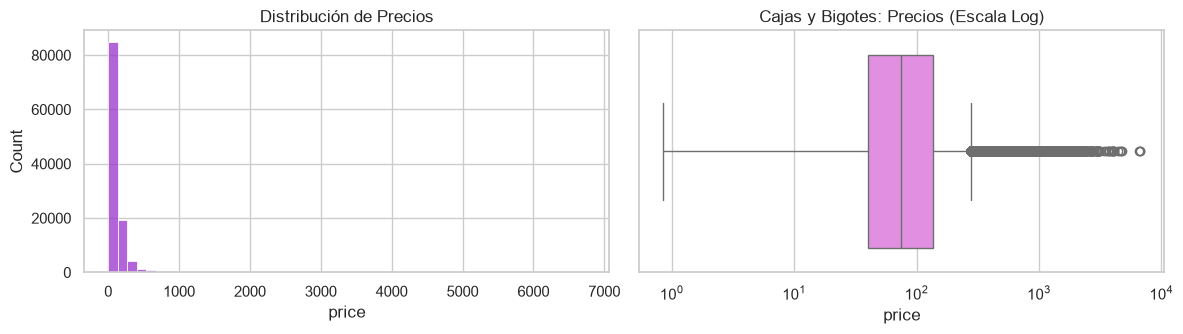

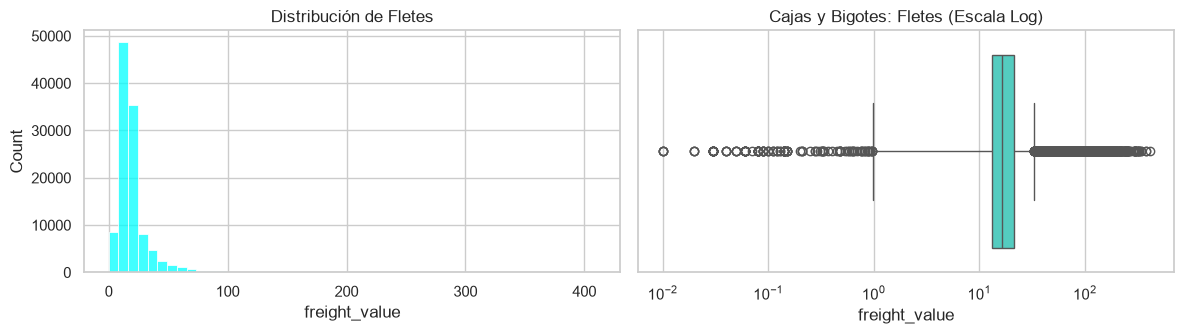

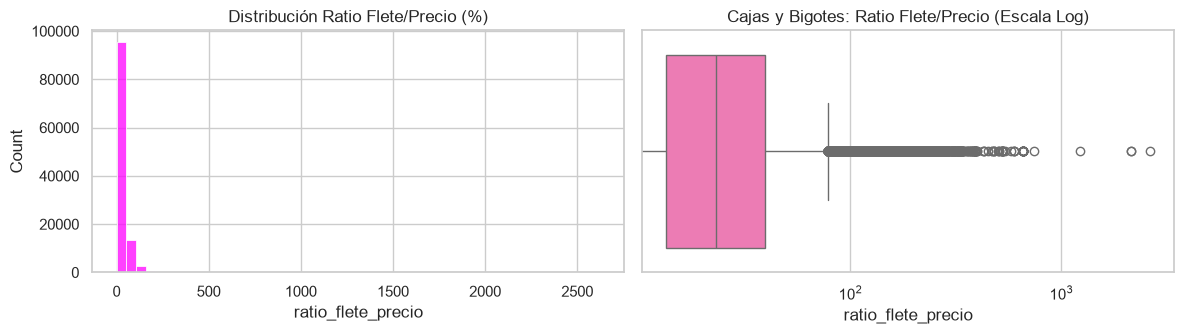

In [16]:
# Escribe aquí el código para construir las visualizaciones que consideren pertinentes.
import matplotlib.pyplot as plt 
import seaborn as sns 

# 1. Precios (price)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df['price'], bins=50, color='darkorchid', ax=axes[0])
axes[0].set_title('Distribución de Precios')
sns.boxplot(x=df['price'], color='violet', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Cajas y Bigotes: Precios (Escala Log)')
plt.tight_layout()
plt.show()

# 2. Fletes (freight_value)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df['freight_value'], bins=50, color='aqua', ax=axes[0])
axes[0].set_title('Distribución de Fletes')
sns.boxplot(x=df['freight_value'], color='turquoise', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Cajas y Bigotes: Fletes (Escala Log)')
plt.tight_layout()
plt.show()

# 3. Ratio Flete / Precio (%)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df['ratio_flete_precio'], bins=50, color='magenta', ax=axes[0])
axes[0].set_title('Distribución Ratio Flete/Precio (%)')
sns.boxplot(x=df['ratio_flete_precio'], color='hotpink', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Cajas y Bigotes: Ratio Flete/Precio (Escala Log)')
plt.tight_layout()
plt.show()

,Frecuencia,Porcentaje (%)
order_item_id,,
1,98666,87.59
2,9803,8.70
3,2287,2.03
4,965,0.86
5,460,0.41
6,256,0.23
7,58,0.05
8,36,0.03
9,28,0.02



Top 10 Vendedores con más ítems despachados:
seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
Name: count, dtype: int64

Top 10 Productos más vendidos:
product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: count, dtype: int64


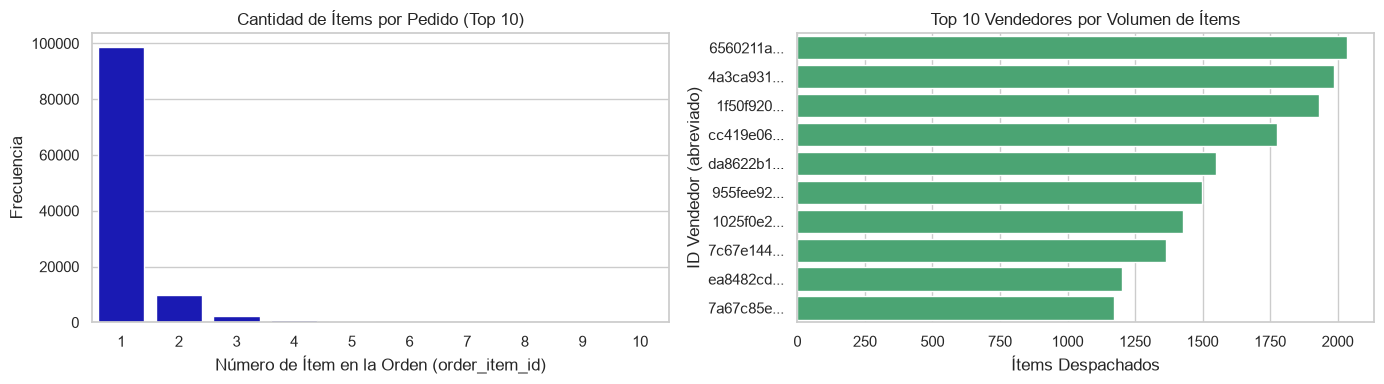

In [17]:
# Escribe aquí el código para analizar las variables categóricas y construir sus visualizaciones.
conteo_items = df['order_item_id'].value_counts().head(10)
porcentaje_items = (df['order_item_id'].value_counts(normalize=True).head(10) * 100).round(2)

display(pd.DataFrame({
    'Frecuencia': conteo_items,
    'Porcentaje (%)': porcentaje_items
}))
print("\nTop 10 Vendedores con más ítems despachados:")
print(df['seller_id'].value_counts().head(10))

print("\nTop 10 Productos más vendidos:")
print(df['product_id'].value_counts().head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=conteo_items.index, y=conteo_items.values, color='mediumblue', ax=axes[0])
axes[0].set_title('Cantidad de Ítems por Pedido (Top 10)')
axes[0].set_xlabel('Número de Ítem en la Orden (order_item_id)')
axes[0].set_ylabel('Frecuencia')

top_vend = df['seller_id'].value_counts().head(10)
sns.barplot(x=top_vend.values, y=top_vend.index.str[:8] + '...', color='mediumseagreen', ax=axes[1])
axes[1].set_title('Top 10 Vendedores por Volumen de Ítems')
axes[1].set_xlabel('Ítems Despachados')
axes[1].set_ylabel('ID Vendedor (abreviado)')

plt.tight_layout()
plt.show()

# Fase 5. Relaciones entre variables

Un análisis exploratorio no debe limitarse a describir columnas por separado. Busca relaciones que permitan comprender mejor el fenómeno.

## 5.1 Formulación de hipótesis

Plantea al menos tres hipótesis que puedan investigar con los datos seleccionados.

Para cada hipótesis:

- ¿Qué variables necesitas?
- ¿Qué relación esperas encontrar?
- ¿Por qué consideras que podría existir esa relación?
- ¿Qué resultado podría contradecir su hipótesis?

**Hipótesis 1:**
Relación positiva moderada entre el precio del producto y el costo absoluto del flete
- ¿Qué variables necesitas?
Necesito price y freight_value
- ¿Qué relación esperas encontrar?
Una correlación positiva: a medida que aumenta el precio del artículo, el costo absoluto del envío tiende a subir.
- ¿Por qué consideras que podría existir esa relación?
En comercio electrónico, los productos de mayor precio suelen corresponder a artículos más pesados, voluminosos o que requieren mayor seguro y embalaje especializado.
- ¿Qué resultado podría contradecir su hipótesis?
Una correlación cercana a cero o negativa, lo que indicaría que las tarifas de transporte dependen exclusivamente de la distancia geográfica o tarifas planas, sin importar el valor o tamaño del producto.
___________________________________________________________________

**Hipótesis 2:**
Relación inversa entre el precop deñ producto y el peso relativo del flete 
- ¿Qué variables necesitas?
Necesito price y ratio_flete_precio
- ¿Qué relación esperas encontrar?
Una negativa, no lineal: en los productos de bajo precio, el flete representa un porcentaje mucho más alto del valor del artículo, mientras que en los productos costosos este mismo cae de manera drástica.
- ¿Por qué consideras que podría existir esa relación?
El transporte tiene costos fijos mínimos operativos (recolección, guía etc...). Cobrar $15 para un artículo de $10 representa ya un 150% de sobrecosto, mientras que por otro lado cobrar $30 por un artículo de $1000 equivale a apenas el 3%.
- ¿Qué resultado podría contradecir su hipótesis?
Que el resultado ratio_flete_precio se mantenga constante en todos los rangos de precios porque significaría que Olist cobra el flete com una comisión porcentual fija sobre el valor del producto.
____________________________________________________________________

**Hipótesis 3:**
Economías de escalas logísticas en pedidos con múltiples ítems
- ¿Qué variables necesitas?
Necesito orden_item_id y freight_value (o la variable que cree de ratio flete)
- ¿Qué relación esperas encontrar?
Que a medida que aumenta el número de ítems dentro de una misma orden el costo del flete por unidad tienda a estabilizarse o ser menor que en pedidos de un solo ítem.
- ¿Por qué consideras que podría existir esa relación?
Al consolidar varios artículos en un mismo despacho, el costo base del envío de reparta entre las unidades, generando eficiencia logística.
- ¿Qué resultado podría contradecir su hipótesis?
Que el costo de flete aumente linealmente o sea igual o mayor en ítems adicionales, demostrando que la plataforma cobra el envío de manera independiente por cada unidad comprada sin aplicar descuentos por consolidación de carga.
____________________________________________________________________

In [18]:
# Escribe aquí el código para investigar las hipótesis planteadas.

cols_hipotesis = ['price', 'freight_value', 'ratio_flete_precio', 'order_item_id']
correlacion = df[cols_hipotesis].corr().round(2)
display(correlacion)

,price,freight_value,ratio_flete_precio,order_item_id
price,1.00,0.41,-0.29,-0.06
freight_value,0.41,1.00,0.09,-0.03
ratio_flete_precio,-0.29,0.09,1.00,0.12
order_item_id,-0.06,-0.03,0.12,1.00


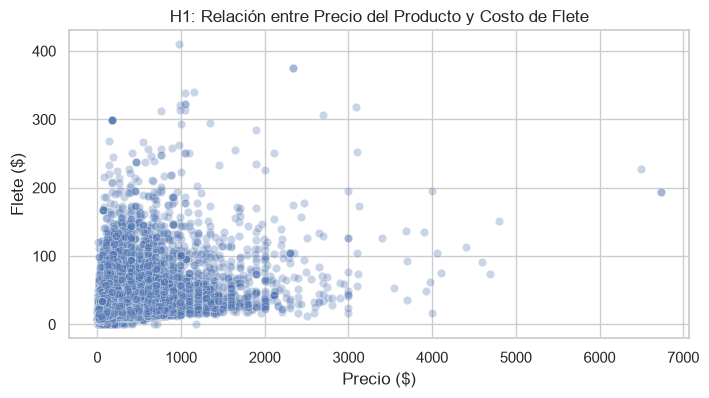

In [19]:
#Hipótesis 1: Precio vs Costo del flete
plt.figure(figsize=(8, 4))
sns.scatterplot(x='price', y='freight_value', data=df, alpha=0.3, color='#4C72B0')
plt.title('H1: Relación entre Precio del Producto y Costo de Flete')
plt.xlabel('Precio ($)')
plt.ylabel('Flete ($)')
plt.show()

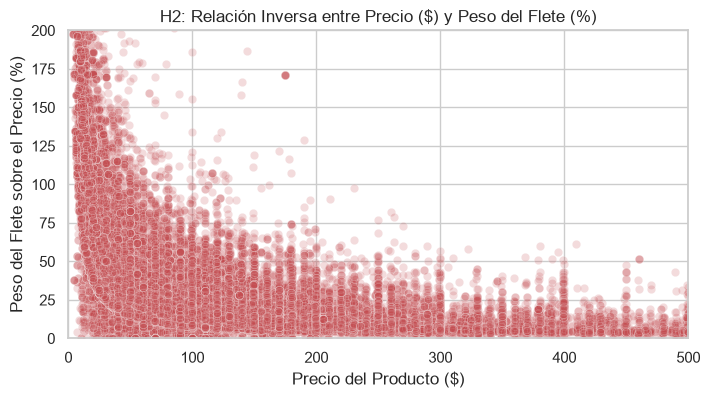

In [20]:
# Hipótesis 2: Precio vs. Peso relativo del flete (%)
plt.figure(figsize=(8, 4))
sns.scatterplot(x='price', y='ratio_flete_precio', data=df, alpha=0.2, color='#C44E52')
plt.xlim(0, 500)   # Zoom en precios de $0 a $500
plt.ylim(0, 200)   # Zoom en peso del flete de 0% a 200%
plt.title('H2: Relación Inversa entre Precio ($) y Peso del Flete (%)')
plt.xlabel('Precio del Producto ($)')
plt.ylabel('Peso del Flete sobre el Precio (%)')
plt.show()

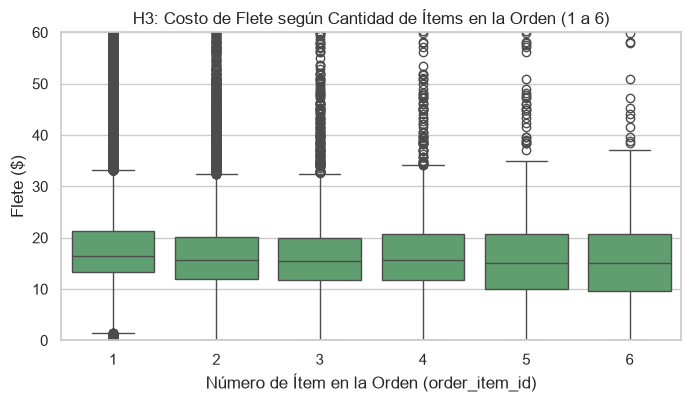

In [21]:
# Hipótesis 3: Número de ítems en la orden vs. Costo de flete
plt.figure(figsize=(8, 4))
sns.boxplot(x='order_item_id', y='freight_value', data=df[df['order_item_id'] <= 6], color='#55A868')
plt.ylim(0, 60)  # Hacemos zoom de $0 a $60 para ver bien las medianas y cajas
plt.title('H3: Costo de Flete según Cantidad de Ítems en la Orden (1 a 6)')
plt.xlabel('Número de Ítem en la Orden (order_item_id)')
plt.ylabel('Flete ($)')
plt.show()

# Fase 6. Análisis temporal, segmentación o análisis geográfico

No todos los análisis necesitan abordar las tres perspectivas. Seleccionen las que tengan sentido para su pregunta de negocio y para las variables disponibles.

## 6.1 Análisis temporal

1. ¿Qué variables contienen fechas?
La variable de shipping_limit_date que convertí anteriormente. 

Registra la fechay hora límite que el vendedor tiene para entregar el pedido.

2. ¿Qué periodos pueden analizarse?

El registro completo me dio como mínimo al 19 de septiembre de 2016 y como máximo al 9 de abril de 2020. Sin embargo, la operación comercial real y continua se concentra en un periodo de 24 meses que son septiembre de 2016 y septiembre de 2018.

3. ¿Cómo cambia el comportamiento a través del tiempo?

Se observa una tendencia de crecimiento acelerado y sostenido: la plataforma pasa de despachar 681 ítems en enero de 2017 a superar 7300 ítems mensuales a final de ese año alcanzando su punto máximo e histórico en agosto de 2018 con 8815 ítems. El flete promedio se mantuvo entre los 18.85 y los 23.04

4. ¿Existen temporadas o periodos con comportamientos diferentes?

Sí existen, hay tres momentos destacados. El priemro es el paso de octubre a noviembre a diciembre en 2017 donde el volumen subió de 5189 a 7355 y luego 7726. El segundo cuando hubieron repuntes en marzo, mayo y agosto de 2018 y el tercero cuando en septiembre de 2018 cayó abruptamente el volumen para luego solo aparecer 4 registros aislados en 2020.

5. ¿Qué eventos o condiciones podrían explicar esos cambios?

El crecimiento de 2017/2018 refleja la expansión comercial que tuvo en Brasil el mercado Olist impulsado por eventos como viernes negro, navidad, día de la madre o del padre. La caída en septiembre de 2018 corresponde en mi opinión al corte de recolección para Kaggle, mientras que los registros de 2020 pueden ser programados o preventas atípicas según lo que investigué.

6. ¿Qué limitaciones tiene la información temporal disponible?

Esta variable mide sólamente el plazo máximo de despacho que se le asigna al vendedor, pero no nos deja saber la fecha en la que la compra fue realizada, el tiempo real que el producto estuvo en tránsito y tampoco si hubo retrasos en la entrega final. Tal vez si hubiese unido la tabla orders esto hubiera sido fácil de consultar.

**Pregunta temporal que desean investigar:**

____________________________________________________________________

Fecha mínima: 2016-09-19 00:15:34
Fecha máxima: 2020-04-09 22:35:08


,total_items,flete_promedio,ratio_promedio
mes,,,
2016-09,4,6.01,11.26
2016-10,365,20.18,29.93
2016-12,1,8.72,80.00
2017-01,681,17.73,35.47
2017-02,1866,19.69,32.80
2017-03,2751,19.37,33.92
2017-04,2364,18.91,32.59
2017-05,4150,19.41,33.10
2017-06,3801,19.63,32.47


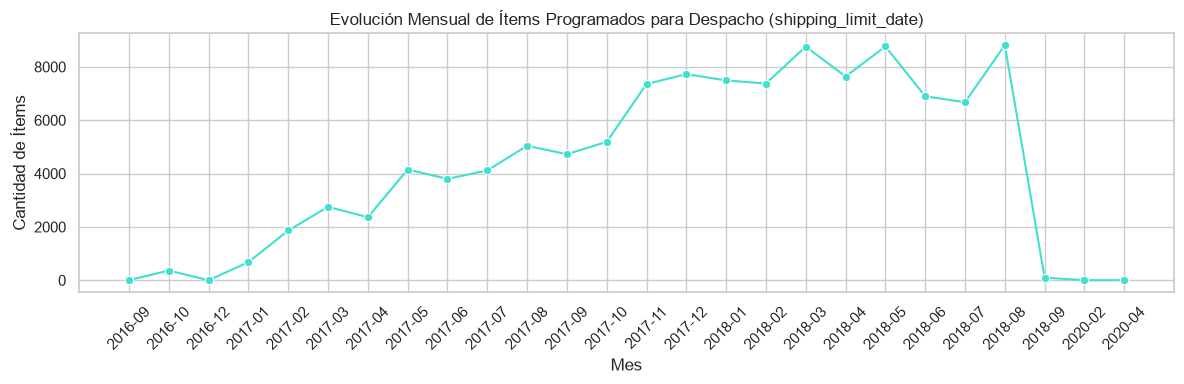

In [22]:
# Escribe aquí el código para desarrollar el análisis temporal, si aplica.
#Establezco el rango de fechas de las que dispongo con mx y min.
print("Fecha mínima:", df['shipping_limit_date'].min())
print("Fecha máxima:", df['shipping_limit_date'].max())

#Lo agrupo por meses para tener claro en volumen
df['mes'] = df['shipping_limit_date'].dt.to_period('M').astype(str)
resumen_mensual = df.groupby('mes').agg(
    total_items=('order_item_id', 'count'),
    flete_promedio=('freight_value', 'mean'),
    ratio_promedio=('ratio_flete_precio', 'mean')
).round(2)
display(resumen_mensual)

#Grafico la evolución mensual del volumen de ítems despachados
plt.figure(figsize=(12, 4))
sns.lineplot(x=resumen_mensual.index, y=resumen_mensual['total_items'], marker='o', color='turquoise')
plt.xticks(rotation=45)
plt.title('Evolución Mensual de Ítems Programados para Despacho (shipping_limit_date)')
plt.xlabel('Mes')
plt.ylabel('Cantidad de Ítems')
plt.tight_layout()
plt.show()

## 6.2 Segmentación

1. ¿Qué grupos tendría sentido comparar?

Los productos económicos frente a los de gama media y gama alta, para evaluar cómo se comporta la carga logística en cada segmento de precio.

2. ¿Qué criterio utilizarán para crear los segmentos?

Cortes de precio basados en la distribución de cuartiles del dataset, con umbrales en %50 y $150, logrando tres grupo representativos de la oferta de marketplace.

3. ¿Qué diferencias existen entre los grupos?

El costo sube moderadamente, sin embargo, el peso porcentual del envío (el que calcula la variable que cree) cae de manera drástica a medida que aumenta el valor del producto. Mientras que el segmento  Alto 22455 ítems el flete promedio sube a $30.38, pero su peso sobre el precio cae al 8.89%; el medio concentra el mayor volumen de transacciones con 50878 ítems, flete promedio de $19.44 y ratio mediano de 19.37%. En contraste, en el segmento económico con 39317 ítems el flete promedio es de $14.77, pero, representa casi la mitad del valor del producto (45.59% de mediana).

4. ¿Qué segmento presenta el comportamiento más particular?

El segmento económico, ya que agrupa más de un tercio de las ventas del marketplace con 39317 ítems con precio promedio de $31.44, pero enfrenta una barrera logística crítica donde el envío equivale típicamente al 45.59% del precio del artículo.

5. ¿Qué decisión podría tomarse a partir de esas diferencias?

Implementar estrategias de venta cruzada o cross-selling, paquetes o umbrales mínimos de compra para envío gratis en el segmento económico, incentivando que el cliente agrupe varios artículos pequeños y diluya el impacto del flete.

**Criterio de segmentación seleccionado:**


In [23]:
# Escribe aquí el código para desarrollar la segmentación, si aplica.
df['segmento_precio'] = pd.cut(
    df['price'],
    bins=[0, 50, 150, 7000],
    labels=['1. Económico (<= $50)', '2. Medio ($50 - $150)', '3. Alto (> $150)']
)

tabla_segmentos = df.groupby('segmento_precio', observed=False).agg(
    cantidad_items=('price', 'count'),
    precio_promedio=('price', 'mean'),
    flete_promedio=('freight_value', 'mean'),
    ratio_flete_mediana=('ratio_flete_precio', 'median')
).round(2)

display(tabla_segmentos)


,cantidad_items,precio_promedio,flete_promedio,ratio_flete_mediana
segmento_precio,,,,
1. Económico (<= $50),39317,31.44,14.77,45.59
2. Medio ($50 - $150),50878,93.12,19.44,19.37
3. Alto (> $150),22455,339.25,30.38,8.89


## 6.3 Análisis geográfico

1. ¿Qué variables permiten estudiar ubicaciones?
2. ¿Qué diferencias encuentran entre regiones?
3. ¿La ubicación parece relacionarse con alguna variable de interés?
4. ¿Qué limitaciones tiene la información geográfica?
5. ¿Qué conclusiones no sería válido afirmar con estos datos?

**Pregunta geográfica que desean investigar:**


In [24]:
# Escribe aquí el código para desarrollar el análisis geográfico, si aplica.
#En este caso, como empecé a desarrollar el trabajo sólo con las variables que cre+í de mi carrera profe
#No pensé en revisar un análisis geográfico incluyendo otra base de datos...

# Fase 7. Construcción de hallazgos

En esta fase deben dejar de pensar únicamente en funciones de Python y empezar a pensar como analistas.

Selecciona entre cinco y ocho hallazgos relevantes.

Para cada hallazgo responde:

1. ¿Qué encontraste?
2. ¿Qué evidencia concreta respalda el hallazgo?
3. ¿Qué variables y operaciones utilizaste?
4. ¿Por qué es importante?
5. ¿Qué explicación posible tiene?
6. ¿Qué decisión podría tomar una organización con esta información?
7. ¿Qué tan seguros están de su interpretación?

**Hallazgo 1:**
1. ¿Qué encontraste?

Un sobrecosto logístico muy fuerte en los productos más baratos.

2. ¿Qué evidencia concreta respalda el hallazgo?

Los artículos económicos de hasta $50 suman 39317 ventas con un precio promedio de $31.44 y un flete promedio de $14.77, lo que hace que el envío equivalga típicamente al 45.59% del valor del producto. En los artículos de más de $150, ese porcentaje baja al 8.89%

3. ¿Qué variables y operaciones utilizaste?

Utilicé price, freight_value y ratio_flete_precio y las operé con correlaciones, segmentación y groupby

4. ¿Por qué es importante?

Porque pagar casi la mitad del precio del producto solo en envío frena la desición de compra del cliente, lo cual no le sirve a la empresa.

5. ¿Qué explicación posible tiene?

El transporte tiene costos mínimos fijos de recolección y última milla, esto no puede bajar a pesar de que el artículo sea económico.

6. ¿Qué decisión podría tomar una organización con esta información?

En mi opinión crear combos de productos o establecer un monto mínimo de compra para ofrecer envío gratis en artículos económicos.

7. ¿Qué tan seguros están de su interpretación?

Estoy bastante segura, ya que el patrón se confirma en los 112650 registos y en la correlación que dio negativa en -0.29
____________________________________________________________________

**Evidencia:**
Al cruzar el precio con nuestro indicador ratio_flete_precio, la correlación dio negativa en -0.29. Además, en la segmentación vimos que los productos económicos de hasta $50 suman 39,317 ventas con un precio promedio de $31.44 y un flete promedio de $14.77, lo que hace que el envío represente típicamente el 45.59% del valor del artículo. En cambio, en los productos de más de $150, el peso del flete baja al 8.89%
____________________________________________________________________

**Interpretación e implicación:**
Esto pasa porque todo envío tiene costos mínimos fijos de transporte, sin importar qué tan barato sea el producto. Para el cliente esto frena la compra; por eso, Olist debería crear combos o poner un monto mínimo de compra para dar envío gratis en productos económicos.
____________________________________________________________________

**Hallazgo 2:**
1. ¿Qué encontraste?

No existe ahorro en el envío para el cliente cuando compra varios artículos en una misma orden.

2. ¿Qué evidencia concreta respalda el hallazgo?

El gráfico de cajas y bigotes mostró que la mediana del flete se mantiene igual en unos $15 a $16 desde el primer ítem hasta el sexto, y la correlación es de apenas un -0.03%. Además, el 87.59% de los registros correspondern a compras de un único artículo.

3. ¿Qué variables y operaciones utilizaste?

Usé order_item_id y freight_value, operadas mediante frecuencia relativa, correlación y el diagrama de cajas y bigotes. 

4. ¿Por qué es importante?

Porque desincentiva a que los compradores agreguen más productos a sus carritos de compra ya que implicaría aún más valor de envío.

5. ¿Qué explicación posible tiene?

La plataforma hace un cobro individial por cada artículo en lugar de prorratear o repartir el costo de una sola caja o guía de transporte. (aunque también es posible que se hagan todos los envíos por aparte lo que en mi opinión es un desperdicio pues podrían hacer una consolidación de carga y hacerlo más eficiente para todos).

6. ¿Qué decisión podría tomar una organización con esta información?

Ofrecer descuentos progresivos en el envío a partir del segunto artículo para aumentar el tamaño promedio de pedidos.

7. ¿Qué tan seguros están de su interpretación?

Bastante segura, respecto a lo que paga el cliente, sin embargo sí creo que habría que revisar guías físicas de envío para confirmar si el vendedor está obteniendo ganancia extra al consolidar paquetes e igual cobrar fletes aparte.

____________________________________________________________________

**Evidencia:**
Al comparar la cantidad de ítems por pedido con el valor del flete, la correlación es casi cero, de -0.03, y el gráfico de cajas muestra que el envío típico se mantiene igual en unos $15 o $16 desde el primer artículo hasta el sexto.
____________________________________________________________________

**Interpretación e implicación:**
La plataforma cobra el flete por separado para cada unidad y no hace ningún descuento al comprador por llevar varios productos, lo que explica que el 87.59% de las compras sean de un solo artículo. Si el vendedor envía todo en una misma caja con una sola guía, ahí tiene una ganancia extra, pero si no, se pierde una oportunidad de vender más ofreciendo descuentos en envíos múltiples.
____________________________________________________________________

**Hallazgos adicionales:**
**Hallazgo 3:**
1. ¿Qué encontraste?

Los precios y fletes tienen un sesgo fuerte hacia la derecha y el negocio se concentra en productos de rango medio

2. ¿Qué evidencia concreta respalda el hallazgo?

El precio promedio es de $120.65 frente a una mediana de $74.99, y el flete promedio es de $19.99 frente a una mediana de $16.26. El segmento medio entre $50 y $150 concentra 50,878 ítems, mientras existen extremos de precios hasta $6,735 y fletes de $409.68

3. ¿Qué variables y operaciones utilizaste?

rice y freight_value, operados con medidas de tendencia central, cuartiles, histogramas, diagramas de cajas y segmentación.

4. ¿Por qué es importante?

Porque usar los promedios simples distorciona cualquier proyección financiera o de tarifas logísticas.

5. ¿Qué explicación posible tiene?

Pocos artículos de lujo o muy pesados elevan el promedio general muy por encima del comportamiento típico del mercado.

6. ¿Qué decisión podría tomar una organización con esta 
información?

Usar la mediana como indicador guía para presupuestos y enfocar las estrategias comerciales al segmento medio de precios entre $50 y $150.

7. ¿Qué tan seguros están de su interpretación?

Bastante segura, lo respaldan las estadísticas descriptivas y también las distribuciones gráficas.

____________________________________________________________________

**Evidencia:**
En las estadísticas básicas tanto el precio como el flete tienen la media por encima de la mediana: el precio promedio es de $120.65 frente a una mediana de $74.99, y el flete promedio es de $19.99 frente a una mediana de $16.26. La segmentación también muestra que el grupo medio entre $50 y $150 concentra la mayor parte del negocio con 50878 ítems, mientras existen casos extremos de precios hasta $6,735 y fletes de $409.68.
____________________________________________________________________

**Interpretación e implicación:**
Si la empresa usa promedios simples para hacer presupuestos, los valores extremos van a distorsionar los cálculos. Lo ideal es planear costos y tarifas usando la mediana y enfocarse en el rango medio de $50 a $150, que es el verdadero motor de ventas. 
____________________________________________________________________
**Hallazgo 4:**
1. ¿Qué encontraste?

El precio del artículo no determina por sí solo cuánto cuesta el envío.

2. ¿Qué evidencia concreta respalda el hallazgo?

La correlación entre precio y flete es moderada de 0.41, y en el gráfico de dispersión se ven artículos baratos con envíos superiores a $100 junto a artículos costosos con fletes muy baratos.

3. ¿Qué variables y operaciones utilizaste?

Usé price y freight_value, operadas mediante matriz de correlación y diagrama de dispersión.

4. ¿Por qué es importante?

Porque demuestra que el valor comercial no basta para estimar un costo logístico.

5. ¿Qué explicación posible tiene?

Las tarifas de transporte dependen más del peso físico, el volumen del paquete y la distancia entre ciudades que del precio del artículo en venta.

6. ¿Qué decisión podría tomar una organización con esta 
información?

Integrar variables de peso, dimensión y ubicación en los modelos de cotización de envío.

7. ¿Qué tan seguros están de su interpretación?

En este diría que medianamente segura, me limita que los datos que elegí no me hablan de medidas físicas ni de ciudades orígen y destino.

____________________________________________________________________

**Evidencia:**
El gráfico de dispersión y la correlación de 0.41 entre precio y flete muestran una relación débil, donde varios productos baratos pagan más de $100 de envío y algunos productos caros tienen fletes bajos.
____________________________________________________________________

**Interpretación e implicación:**
El costo del transporte depende más del peso, el tamaño del paquete y la distancia del viaje que del precio del artículo. Para calcular tarifas más exactas a futuro, conviene cruzar esta base con las tablas de dimensiones físicas y ubicación geográfica que en esta tabla no está disponible.
____________________________________________________________________
**Hallazgo 5:**
1. ¿Qué encontraste?

El volumen de despachos creció aceleradamente entre 2017 y 2018 manteniendo estable el costo promedio del flete

2. ¿Qué evidencia concreta respalda el hallazgo?

Tras el arranque de finales de 2016, los envíos subieron de 681 ítems en enero de 2017 a superar los 7300 mensuales en noviembre y diciembre de ese mismo año llegando a su pico de 8815 artículos en agosto de 2018, mientras el flete se mantuvo estable entre $18.84 y$23.04

3. ¿Qué variables y operaciones utilizaste?

Usé shipping_limit_date, order_item_id y freight_value agrupadas mensualmente con groupby y visualizdas en una tabla.

4. ¿Por qué es importante?

Porque evidencia tanto la capacidad de crecimiento de la operación como los meses exactos de mayor presión logística.

5. ¿Qué explicación posible tiene?

La expansión de olist en Brasil y el impulso de fechas comerciales.

6. ¿Qué decisión podría tomar una organización con esta información?

Reforzar la capacidad operativa y negociar tarifas con transportadoras antes de los meses pico de mayo, agosto, noviembre y diciembre.

7. ¿Qué tan seguros están de su interpretación?

Bastante segura, respecto a los volumenes programados para despacho sólo me faltaría validar las fechas reales de entrega.

____________________________________________________________________

**Evidencia:**
Al analizar la fecha límite de despacho, las ventas pasaron de un arranque bajo a finales de 2016 a superar los 7300 ítems mensuales en noviembre y diciembre de 2017, llegando a un pico de 8815 ítems en agosto de 2018. Durante toda esa subida, el flete promedio se mantuvo estable entre $18.84 y $23.04.
____________________________________________________________________

**Interpretación e implicación:**
La operación logística soportó muy bien el aumento de demanda en fechas comerciales clave como Black Friday, Navidad, Día de la Madre y Día del Padre sin encarecer los envíos. La empresa debe reforzar su capacidad operativa justo antes de esos meses pico. 
____________________________________________________________________

,cantidad_items,precio_promedio,flete_promedio,ratio_flete_mediana
segmento_precio,,,,
1. Económico (<= $50),39317,31.44,14.77,45.59
2. Medio ($50 - $150),50878,93.12,19.44,19.37
3. Alto (> $150),22455,339.25,30.38,8.89


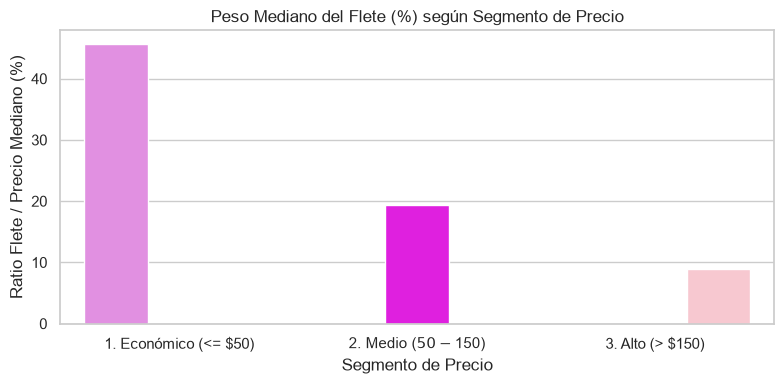

In [25]:
# Incluye aquí las tablas o visualizaciones finales que respalden tus hallazgos.

display(tabla_segmentos)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=tabla_segmentos.index,
    y=tabla_segmentos['ratio_flete_mediana'],
    hue=tabla_segmentos.index,
    palette=['violet', 'magenta', 'pink'],
    legend=False
)
plt.title('Peso Mediano del Flete (%) según Segmento de Precio')
plt.xlabel('Segmento de Precio')
plt.ylabel('Ratio Flete / Precio Mediano (%)')
plt.tight_layout()
plt.show()

# Fase 9. Conclusiones y recomendaciones

## 9.1 Conclusiones

1. ¿Cuál era el problema o pregunta inicial?
2. ¿Qué lograron comprender a partir de los datos?
3. ¿Qué hipótesis pudieron respaldar y cuáles no?
4. ¿Qué hallazgo consideran más importante?


**Conclusión 1:**
1. ¿Cuál era el problema o pregunta inicial?

Entender cómo se comportan los precios de venta y los costos de envío en las transacciones de Olist y evaluar qué tanto pesa el flete sobre el bolsillo del consumidor según el tipo de pedido.

2. ¿Qué lograron comprender a partir de los datos?

Que el flete no sube proporcionalmente al precio, lo que afecta directamente a los artículos económicos y hace que la estructura de costos dependa más de tarifas base de transporte y características físicas que del valor comercial del producto.

3. ¿Qué hipótesis pudieron respaldar y cuáles no?

Por completo respaldé mi hipótesis 2 sobre la relación inversa entre el precio y el peso porcentual del flete, mientras que la 1 solamente de manera parcial y débil porque muchos artículos baratos tienen envíos costosos.

4. ¿Qué hallazgo consideran más importante?

El sobrecosto logístico en el segmento económico de hasta $50 donde el flete representa el 45.59% del valor del producto típicamente, frenando las compras.
____________________________________________________________________

**Conclusión 2:**
1. ¿Cuál era el problema o pregunta inicial?

Determinar si agrupar varios artículos en una misma orden genera ahorros en el envío y cómo se distribuye el volumen de ventas a lo largo del tiempo

2. ¿Qué lograron comprender a partir de los datos?

Que Olist cobra un flete independiente por cada unidad agregada al carito sin trasladar realizar descuentos de consolidación de compra, y, que la plataforma crecion de manera acelerada hasta alcanzar picos de hasta más de 8800 ítems al mes manteniendo fletes estables de entre $19 a $23.

3. ¿Qué hipótesis pudieron respaldar y cuáles no?

Se rechazó la hipótesis 3, ya que las cajas de distribución del flete permanecieron planas en $15 a $16 sin importar si el pedido tenía uno o seis ítems.

4. ¿Qué hallazgo consideran más importante?

La ausencia de economías de escala realizadas al comprador en órdenes de multiples artículos, lo que explica que el 87.59% de las transacciones sean compras de un solo artículo.
____________________________________________________________________

**Conclusión 3:**
1. ¿Cuál era el problema o pregunta inicial?

Identificar el comportamiento estadístico real de las ventas para evitar sesgos en la toma de decisiones comerciales y logísticas.

2. ¿Qué lograron comprender a partir de los datos?

Que tanto el precio como el flete tienen un sesgo fuerte hacia la derecha por culpa de casos extremos, por lo que el negocio real se mueve en el rango medio de $50 a $150 y debe medirse con la mediana y los cuartiles en lugar de promedios simple

3. ¿Qué hipótesis pudieron respaldar y cuáles no?

En conjunto, los datos confirmaron que la sensibilidad al flete depende del segmento de precio y no de la cantidad de ítems comprados, validando la necesidad de segmentar el catálogo para analizarlo correctamente.

4. ¿Qué hallazgo consideran más importante?

a fuerte concentración operativa en el segmento medio entre $50 y $150, que reúne 50,878 ítems y constituye el verdadero motor de ingresos de Olist.
____________________________________________________________________

## 9.2 Recomendaciones

Formula al menos tres recomendaciones dirigidas a una persona responsable de tomar decisiones.

Cada recomendación debe estar conectada con un hallazgo y explicar qué acción se propone y qué se espera mejorar.

**Recomendación 1:**

Con base en el hallazgo 1 sobre el sobrecosto logístico del 45.59% en productos económicos de hasta $50, recomiendo a la Gerencia Comercial y de Marketing crear combos de artículos complementarios y fijar un monto mínimo de compra de $60 o $70 para dar envío gratis en este segmento. Con esto se logrará reducir el abandono de carritos por envíos costosos, aumentar el valor promedio por pedido y diluir el costo fijo del transporte entre varias unidades.
____________________________________________________________________

**Recomendación 2:**

Para el segundo hallazgo en el que se evidenció que no existe ahorro en el envío al comprar múltiples artículos en una misma orden, le sugiero a la Dirección de Operaciones y Logística implementar una tarifa escalonada con descuentos progresivos a partir del segundo producto comprado al mismo vendedor cuando se despachen en un solo paquete. Esta acción permitirá incentivar que los clientes agreguen más artículos al carrito en lugar de hacer compras individuales, elevando el volumen de ventas sin disparar los costos reales de transporte.
____________________________________________________________________

**Recomendación 3:**

En relación a los hallazgos 4 y 5 sobre el peso físico de paquetes y los pios de demanda, propongo a la Gerencia de Planeación Financiera integrar las variables de dimensiones y ubicación geográfica de las otras tablas de Olist en los modelos de cotización, usando la mediana como guía para los presupuestos y reforzando los acuerdos con transportadoras antes de mayo, agosto, noviembre y diciembre. De esta forma se obtendrán tarifas de envío más exactas sin pérdidas por volumen y se garantizarán despachos fluidos en temporadas altas.
____________________________________________________________________
